In [1]:
%pip install yfinance pandas numpy matplotlib statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [3]:
tickers = ["JPM", "BAC"]

data = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-11-14",
    auto_adjust=True,
    progress=False
)

data.head()

Price           Close                   High                    Low  \
Ticker            BAC         JPM        BAC         JPM        BAC   
Date                                                                  
2020-01-02  30.274988  117.313942  30.291978  117.322265  29.977676   
2020-01-03  29.646389  115.765800  29.858756  116.510571  29.527461   
2020-01-06  29.603912  115.673782  29.646388  115.707262  29.196169   
2020-01-07  29.408533  113.707237  29.663372  115.364139  29.332081   
2020-01-08  29.705847  114.594284  29.892727  115.129849  29.349069   

Price                        Open                Volume            
Ticker             JPM        BAC         JPM       BAC       JPM  
Date                                                               
2020-01-02  115.792326  30.028642  116.233011  37614200  10803700  
2020-01-03  114.711411  29.714345  115.062874  50357900  10386800  
2020-01-06  114.226085  29.230148  114.276293  42185000  10259000  
2020-01-07  113.657030  29.476492  114.878781  34149000  10531300  
2020-01-08  113.472947  29.366059  113.556621  45311600   9695300

In [4]:
prices = data["Close"].copy()

prices = prices[["JPM", "BAC"]].dropna()

prices.head()

Ticker,JPM,BAC
Date,,
2020-01-02,117.313942,30.274988
2020-01-03,115.765800,29.646389
2020-01-06,115.673782,29.603912
2020-01-07,113.707237,29.408533
2020-01-08,114.594284,29.705847


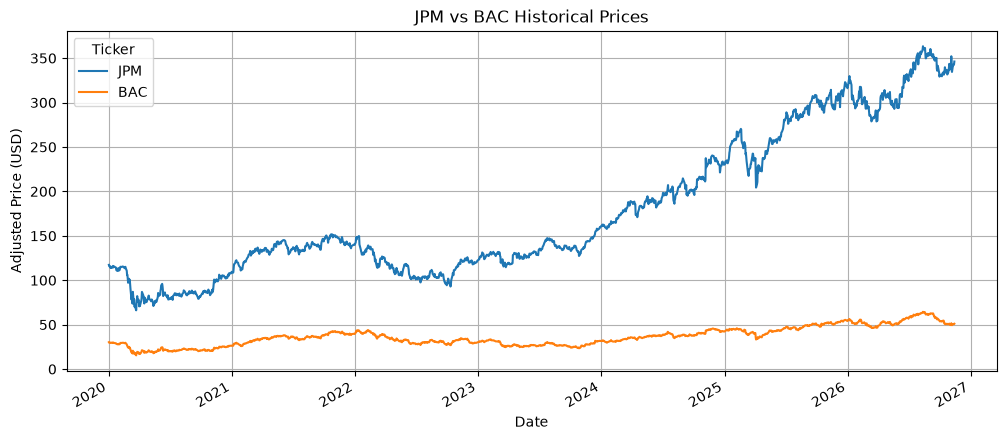

In [5]:
prices.plot(figsize=(12, 5))

plt.title("JPM vs BAC Historical Prices")
plt.xlabel("Date")
plt.ylabel("Adjusted Price (USD)")
plt.grid(True)
plt.show()

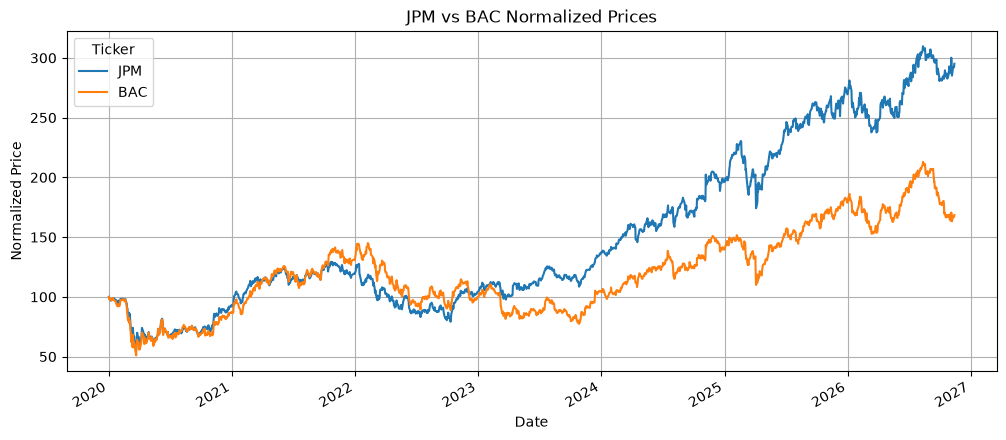

In [6]:
normalized = prices / prices.iloc[0] * 100

normalized.plot(figsize=(12, 5))

plt.title("JPM vs BAC Normalized Prices")
plt.xlabel("Date")
plt.ylabel("Normalized Price")
plt.grid(True)
plt.show()

In [3]:
import pandas as pd

url = "https://raw.githubusercontent.com/datasets/s-and-p-500-companies/main/data/constituents.csv"

sp500 = pd.read_csv(url)

sp500.head()

,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


In [4]:
tickers = sp500["Symbol"].str.replace(
    ".", "-", regex=False
).tolist()

print("Number of tickers:", len(tickers))
print("First 10 tickers:", tickers[:10])

Number of tickers: 503
First 10 tickers: ['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


In [5]:
import yfinance as yf

data = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-11-14",
    auto_adjust=True,
    progress=True,
    threads=True
)

data.head()

[*********************100%***********************]  503 of 503 completed


Price           Close                                                   \
Ticker              A       AAPL       ABBV ABNB        ABT       ACGL   
Date                                                                     
2020-01-02  81.930473  72.216660  67.794464  NaN  76.311333  41.268997   
2020-01-03  80.615021  71.514580  67.150963  NaN  75.381042  41.221451   
2020-01-06  80.853302  72.084435  67.680901  NaN  75.775970  41.383106   
2020-01-07  81.101189  71.745399  67.294800  NaN  75.354706  41.040779   
2020-01-08  81.901886  72.899513  67.771736  NaN  75.661880  40.631893   

Price                                                      ...   Volume  \
Ticker             ACN        ADBE         ADI        ADM  ...       WY   
Date                                                       ...            
2020-01-02  187.126862  334.429993  107.170677  38.015945  ...  4973500   
2020-01-03  186.815247  331.809998  105.284088  37.941746  ...  3111000   
2020-01-06  185.595291  333.709991  104.047134  37.644939  ...  2178600   
2020-01-07  181.588348  333.390015  106.414276  37.191483  ...  2426200   
2020-01-08  181.944489  337.869995  107.375374  36.779251  ...  2299800   

Price                                                                        \
Ticker         WYNN      XEL       XOM      XYL       XYZ      YUM      ZBH   
Date                                                                          
2020-01-02  3006500  2915400  12456400   869500   5264700  1369900  1083972   
2020-01-03  1760500  2422500  17386900   795100   5087100  1145500   992405   
2020-01-06  1357900  2217100  20081900   817300   5905200  1454100   972423   
2020-01-07  1722100  1861100  17387700   662200  10368200  1388600   934519   
2020-01-08  1176200  4828900  15137700  1083200  11899200  1521500   936064   

Price                        
Ticker        ZBRA      ZTS  
Date                         
2020-01-02  387800  1576700  
2020-01-03  305300  1274000  
2020-01-06  322600  2334100  
2020-01-07  236300  1224500  
2020-01-08  689600  1766700  

[5 rows x 2515 columns]

In [6]:
prices = data["Close"].copy()

print(prices.shape)

prices.head()

(1727, 503)


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,81.930473,72.216660,67.794464,NaN,76.311333,41.268997,187.126862,334.429993,107.170677,38.015945,...,22.984663,137.416565,50.689568,52.606407,73.531563,63.830002,90.006935,136.851273,259.140015,124.702682
2020-01-03,80.615021,71.514580,67.150963,NaN,75.381042,41.221451,186.815247,331.809998,105.284088,37.941746,...,23.023771,135.378265,50.933338,52.183468,73.964363,63.000000,89.725006,136.493515,256.049988,124.721313
2020-01-06,80.853302,72.084435,67.680901,NaN,75.775970,41.383106,185.595291,333.709991,104.047134,37.644939,...,22.976843,135.110382,50.860195,52.584141,73.485535,62.570000,89.672165,135.704742,258.010010,123.763702
2020-01-07,81.101189,71.745399,67.294800,NaN,75.354706,41.040779,181.588348,333.390015,106.414276,37.191483,...,22.828251,135.751480,50.754581,52.153793,73.209244,64.589996,89.830757,135.585434,256.470001,124.182083
2020-01-08,81.901886,72.899513,67.771736,NaN,75.661880,40.631893,181.944489,337.869995,107.375374,36.779251,...,22.914278,136.603149,50.705811,51.367294,73.457893,67.599998,89.989311,137.209000,247.639999,123.912491


In [7]:
missing_ratio = prices.isna().mean()

missing_ratio.sort_values(ascending=False).head(20)

Ticker
VYLR    0.981471
HONA    0.938043
FDXF    0.930515
Q       0.846555
SNDK    0.744644
GEV     0.616676
SOLV    0.616097
RDDT    0.614360
VLTO    0.547192
GEHC    0.431384
CEG     0.298784
HOOD    0.229299
APP     0.187030
COIN    0.186450
EXE     0.161552
ABNB    0.137811
DASH    0.137232
PLTR    0.108859
CARR    0.030689
OTIS    0.030689
dtype: float64

In [8]:
valid_tickers = missing_ratio[missing_ratio <= 0.05].index

clean_prices = prices[valid_tickers].copy()

print("Before cleaning:", prices.shape)
print("After cleaning:", clean_prices.shape)

Before cleaning: (1727, 503)
After cleaning: (1727, 485)


In [9]:
remaining_missing = clean_prices.isna().sum()

print("Total missing values:", remaining_missing.sum())
print("Stocks with missing values:", (remaining_missing > 0).sum())

remaining_missing[remaining_missing > 0].sort_values(ascending=False).head(10)

Total missing values: 106
Stocks with missing values: 2


Ticker
CARR    53
OTIS    53
dtype: int64

In [10]:
print(prices["CARR"].first_valid_index())
print(prices["OTIS"].first_valid_index())

2020-03-19 00:00:00
2020-03-19 00:00:00


In [11]:
for ticker in ["CARR", "OTIS"]:
    stock = prices[ticker]
    first_date = stock.first_valid_index()

    missing_after = stock.loc[first_date:].isna().sum()

    print(ticker, missing_after)

CARR 0
OTIS 0


In [12]:
clean_prices = clean_prices.loc["2020-03-19":].copy()

print(clean_prices.shape)
print(clean_prices.isna().sum().sum())

(1674, 485)
0


In [13]:
train = clean_prices.loc[:"2024-12-31"].copy()
test = clean_prices.loc["2025-01-01":].copy()

print("Training set:", train.shape)
print("Testing set:", test.shape)

Training set: (1205, 485)
Testing set: (469, 485)


In [14]:
print("Train period:", train.index.min(), "to", train.index.max())
print("Test period:", test.index.min(), "to", test.index.max())

print("Total trading days:", len(train) + len(test))
print("Original trading days:", len(clean_prices))

Train period: 2020-03-19 00:00:00 to 2024-12-31 00:00:00
Test period: 2025-01-02 00:00:00 to 2026-11-13 00:00:00
Total trading days: 1674
Original trading days: 1674


In [15]:
train_ratio = len(train) / len(clean_prices)
test_ratio = len(test) / len(clean_prices)

print("Training ratio:", round(train_ratio * 100, 2), "%")
print("Testing ratio:", round(test_ratio * 100, 2), "%")

Training ratio: 71.98 %
Testing ratio: 28.02 %


In [16]:
clean_prices.to_csv("clean_prices.csv")

print("Saved:", clean_prices.shape)

Saved: (1674, 485)


In [17]:
%pip install -U yfinance pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 20.8 MB/s  0:00:00 22.4 MB/s eta 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
Note: you may need to restart the kernel to use updated packages.


In [18]:
from pathlib import Path
from datetime import date, timedelta
import json
import time
import pandas as pd
import numpy as np
import yfinance as yf

SOURCE = Path("clean_prices.csv")
OUT_DIR = Path("history_download_2010")
PARTS_DIR = OUT_DIR / "batches"
OUT_DIR.mkdir(exist_ok=True)
PARTS_DIR.mkdir(exist_ok=True)

START = "2010-01-01"
END_EXCLUSIVE = (date.today() + timedelta(days=1)).isoformat()
BATCH_SIZE = 20
RETRIES = 3

if not SOURCE.exists():
    raise FileNotFoundError(f"Please put clean_prices.csv beside this Notebook: {Path.cwd()}")

original_tickers = [str(x).strip() for x in pd.read_csv(SOURCE, index_col=0, nrows=0).columns]
original_tickers = list(dict.fromkeys(x for x in original_tickers if x and not x.startswith("Unnamed:")))

if not original_tickers:
    raise ValueError("No stock tickers found in clean_prices.csv columns")

yahoo_symbols = {t: t.replace(".", "-") for t in original_tickers}
batches = [original_tickers[i:i + BATCH_SIZE] for i in range(0, len(original_tickers), BATCH_SIZE)]

print("Original tickers:", len(original_tickers))
print("Download range:", START, "to", END_EXCLUSIVE, "(end exclusive)")
print("Batches:", len(batches))
print("Examples:", original_tickers[:12])

Original tickers: 485
Download range: 2010-01-01 to 2026-11-19 (end exclusive)
Batches: 25
Examples: ['A', 'AAPL', 'ABBV', 'ABT', 'ACGL', 'ACN', 'ADBE', 'ADI', 'ADM', 'ADP', 'ADSK', 'AEE']


In [19]:
def close_for_symbol(downloaded, yahoo_symbol, batch_size):
    if not isinstance(downloaded, pd.DataFrame) or downloaded.empty:
        return None
    columns = downloaded.columns
    if isinstance(columns, pd.MultiIndex):
        if yahoo_symbol in columns.get_level_values(0):
            frame = downloaded[yahoo_symbol]
            return frame["Close"] if "Close" in frame else None
        if yahoo_symbol in columns.get_level_values(1):
            return downloaded[("Close", yahoo_symbol)] if ("Close", yahoo_symbol) in columns else None
        return None
    if batch_size == 1 and "Close" in columns:
        return downloaded["Close"]
    return None


def fetch_batch(tickers):
    symbols = [yahoo_symbols[t] for t in tickers]
    last_error = None
    for attempt in range(RETRIES):
        try:
            downloaded = yf.download(
                tickers=symbols,
                start=START,
                end=END_EXCLUSIVE,
                auto_adjust=True,
                group_by="ticker",
                actions=False,
                progress=False,
                threads=True,
                repair=False,
            )
            series = {}
            for ticker in tickers:
                s = close_for_symbol(downloaded, yahoo_symbols[ticker], len(tickers))
                if s is not None and s.notna().any():
                    series[ticker] = pd.to_numeric(s, errors="coerce")
            if series:
                return pd.DataFrame(series).sort_index()
            last_error = "Empty batch or no Close data"
        except Exception as exc:
            last_error = str(exc)
        time.sleep(2 * (attempt + 1))
    print("  Batch not fully available:", tickers[:3], "...", str(last_error)[:160])
    return pd.DataFrame()


for i, tickers in enumerate(batches, start=1):
    path = PARTS_DIR / f"batch_{i:03d}.csv"
    if path.exists():
        print(f"[{i:02d}/{len(batches)}] Already saved — skipping")
        continue

    data = fetch_batch(tickers)
    if not data.empty:
        data.to_csv(path, index_label="Date")
    else:
        print(f"[{i:02d}/{len(batches)}] No results. This batch will be retried on next run.")
        continue
    missing = sorted(set(tickers) - set(data.columns))
    print(f"[{i:02d}/{len(batches)}] Saved {len(data.columns)}/{len(tickers)} tickers, {len(data)} rows; missing: {missing[:8]}")

print("Batch download finished")

[01/25] Saved 20/20 tickers, 4245 rows; missing: []
[02/25] Saved 20/20 tickers, 4245 rows; missing: []
[03/25] Saved 20/20 tickers, 4245 rows; missing: []
[04/25] Saved 20/20 tickers, 4245 rows; missing: []
[05/25] Saved 20/20 tickers, 4245 rows; missing: []
[06/25] Saved 20/20 tickers, 4245 rows; missing: []
[07/25] Saved 20/20 tickers, 4245 rows; missing: []
[08/25] Saved 20/20 tickers, 4245 rows; missing: []
[09/25] Saved 20/20 tickers, 4245 rows; missing: []
[10/25] Saved 20/20 tickers, 4245 rows; missing: []
[11/25] Saved 20/20 tickers, 4245 rows; missing: []
[12/25] Saved 20/20 tickers, 4245 rows; missing: []
[13/25] Saved 20/20 tickers, 4245 rows; missing: []
[14/25] Saved 20/20 tickers, 4245 rows; missing: []
[15/25] Saved 20/20 tickers, 4245 rows; missing: []
[16/25] Saved 20/20 tickers, 4245 rows; missing: []
[17/25] Saved 20/20 tickers, 4245 rows; missing: []
[18/25] Saved 20/20 tickers, 4245 rows; missing: []
[19/25] Saved 20/20 tickers, 4245 rows; missing: []
[20/25] Save

In [20]:
parts = []
for i in range(1, len(batches) + 1):
    path = PARTS_DIR / f"batch_{i:03d}.csv"
    if path.exists():
        parts.append(pd.read_csv(path, index_col="Date", parse_dates=True))

if not parts:
    raise RuntimeError("No batch files were saved; check internet connection / yfinance output")

present = set().union(*(set(p.columns) for p in parts))
missing_tickers = [t for t in original_tickers if t not in present]
print("Missing from batches:", len(missing_tickers), missing_tickers[:30])

SINGLES_DIR = OUT_DIR / "single_retries"
SINGLES_DIR.mkdir(exist_ok=True)
for j, ticker in enumerate(missing_tickers, start=1):
    cache = SINGLES_DIR / f"{ticker.replace('/', '_')}.csv"
    if cache.exists():
        continue
    one = fetch_batch([ticker])
    if ticker in one.columns and one[ticker].notna().any():
        one[[ticker]].to_csv(cache, index_label="Date")
    print(f"Single retry {j}/{len(missing_tickers)}: {ticker} -> {'OK' if cache.exists() else 'NO DATA'}")


Missing from batches: 0 []


In [21]:
files = sorted(PARTS_DIR.glob("batch_*.csv")) + sorted(SINGLES_DIR.glob("*.csv"))
frames = [pd.read_csv(p, index_col="Date", parse_dates=True) for p in files]
if not frames:
    raise RuntimeError("No input files were available")

raw = pd.concat(frames, axis=1)
raw = raw.loc[:, ~raw.columns.duplicated(keep="last")]
raw.index = pd.DatetimeIndex(raw.index).tz_localize(None).normalize()
raw = raw.loc[~raw.index.duplicated(keep="last")].sort_index()
raw = raw.reindex(columns=original_tickers)
raw = raw.apply(pd.to_numeric, errors="coerce")

OUTPUT_FILE = OUT_DIR / "raw_adjusted_close_2010_present.csv"
raw.to_csv(OUTPUT_FILE, index_label="Date", float_format="%.10g")

coverage = pd.DataFrame({
    "Ticker": raw.columns,
    "Yahoo Symbol": [yahoo_symbols[t] for t in raw.columns],
    "Observations": [int(raw[t].notna().sum()) for t in raw.columns],
    "First Valid Date": [raw[t].first_valid_index() for t in raw.columns],
    "Last Valid Date": [raw[t].last_valid_index() for t in raw.columns],
    "Missing Rate Overall": [round(float(raw[t].isna().mean()), 4) for t in raw.columns],
})
coverage.to_csv(OUT_DIR / "ticker_coverage_report.csv", index=False)

metadata = {
    "source": "Yahoo Finance via yfinance",
    "download_run_date": date.today().isoformat(),
    "requested_start": START,
    "requested_end_exclusive": END_EXCLUSIVE,
    "auto_adjust": True,
    "adjustment_note": "Close from yfinance auto_adjust=True, intended split/dividend adjusted historical close",
    "ticker_list_source": str(SOURCE),
    "requested_tickers": len(original_tickers),
    "available_tickers": int((coverage["Observations"] > 0).sum()),
    "missing_tickers": coverage.loc[coverage["Observations"] == 0, "Ticker"].tolist(),
    "no_global_dropna": True,
    "survivorship_bias_warning": "Today's/listed universe is not historical point-in-time S&P 500 membership",
}
(OUT_DIR / "download_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

print("OUTPUT:", OUTPUT_FILE.resolve())
print("Shape:", raw.shape)
print("First/last dates:", raw.index.min(), raw.index.max())
print("Tickers with data:", metadata["available_tickers"], "/", len(original_tickers))
print("Missing tickers:", metadata["missing_tickers"][:40])
display(coverage.sort_values("Observations").head(20))
display(raw.iloc[:5, :8])

OUTPUT: /Users/liusiming/pairs-trading-strategy/history_download_2010/raw_adjusted_close_2010_present.csv
Shape: (4245, 485)
First/last dates: 2010-01-04 00:00:00 2026-11-17 00:00:00
Tickers with data: 485 / 485
Missing tickers: []


,Ticker,Yahoo Symbol,Observations,First Valid Date,Last Valid Date,Missing Rate Overall
72,CARR,CARR,1676,2020-03-19,2026-11-17,0.6052
340,OTIS,OTIS,1676,2020-03-19,2026-11-17,0.6052
123,DDOG,DDOG,1801,2019-09-19,2026-11-17,0.5757
111,CRWD,CRWD,1870,2019-06-12,2026-11-17,0.5595
438,UBER,UBER,1892,2019-05-10,2026-11-17,0.5543
136,DOW,DOW,1928,2019-03-20,2026-11-17,0.5458
184,FOX,FOX,1933,2019-03-13,2026-11-17,0.5446
185,FOXA,FOXA,1934,2019-03-12,2026-11-17,0.5444
302,MRNA,MRNA,1997,2018-12-07,2026-11-17,0.5296
455,VRT,VRT,2085,2018-08-02,2026-11-17,0.5088


,A,AAPL,ABBV,ABT,ACGL,ACN,ADBE,ADI
Date,,,,,,,,
2010-01-04,19.743519,6.396101,NaN,17.968191,7.601905,30.610773,37.090000,21.703714
2010-01-05,19.529053,6.407160,NaN,17.823011,7.576549,30.799946,37.700001,21.669447
2010-01-06,19.459665,6.305244,NaN,17.922005,7.543795,31.127363,37.619999,21.628330
2010-01-07,19.434433,6.293589,NaN,18.070469,7.499420,31.098276,36.889999,21.457008
2010-01-08,19.428129,6.335429,NaN,18.162849,7.484628,30.974569,36.689999,21.580364


In [22]:
print("Missing price observations:", int(raw.isna().sum().sum()))
print("Nonpositive observed prices:", int((raw <= 0).sum().sum()))
print("Stocks with at least 1 observation:", int(raw.notna().any().sum()))
print("Stocks with at least 10 years of observations (approx):", int((raw.notna().sum() >= 2520).sum()))
print("Earliest price row:", raw.index.min())
print("Latest price row:", raw.index.max())


Missing price observations: 76028
Nonpositive observed prices: 0
Stocks with at least 1 observation: 485
Stocks with at least 10 years of observations (approx): 469
Earliest price row: 2010-01-04 00:00:00
Latest price row: 2026-11-17 00:00:00
